In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("resume-dataset/Resume/Resume.csv")
df = df.rename(columns={
    "Category": "label",
    "Resume_str": "text"
})

print(df.columns)

Index(['ID', 'text', 'Resume_html', 'label'], dtype='object')


# drop unused fields
df = df.drop(columns=["Resume_html", "ID"], errors='ignore')

In [6]:
# remove rows with missing values
df = df.dropna(subset=["text", "label"]).reset_index(drop=True)

In [7]:
print(df.columns)

Index(['ID', 'text', 'label'], dtype='object')


In [8]:
print(df.head())

         ID                                               text label
0  16852973           HR ADMINISTRATOR/MARKETING ASSOCIATE\...    HR
1  22323967           HR SPECIALIST, US HR OPERATIONS      ...    HR
2  33176873           HR DIRECTOR       Summary      Over 2...    HR
3  27018550           HR SPECIALIST       Summary    Dedica...    HR
4  17812897           HR MANAGER         Skill Highlights  ...    HR


In [9]:
print(df['label'].value_counts())

label
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   118
FITNESS                   117
AVIATION                  117
SALES                     116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [12]:
print(df['text'].iloc[0][:800])

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as   


In [13]:
import pdfplumber, os, glob
import pandas as pd
from tqdm import tqdm

In [14]:
pdf_dir = "resume-dataset/data"   # adjust if PDFs are in folders
out_rows = []

for pdf_path in tqdm(glob.glob(os.path.join(pdf_dir, "**/*.pdf"), recursive=True)):
    try:
        with pdfplumber.open(pdf_path) as pdf:
            text = "\n".join(page.extract_text() or "" for page in pdf.pages)
        label = os.path.basename(os.path.dirname(pdf_path))  # if dataset stores PDFs in label folders
        out_rows.append({"path": pdf_path, "label": label, "text": text})
    except Exception as e:
        print("error", pdf_path, e)

df = pd.DataFrame(out_rows)
df.to_csv("resumes_extracted.csv", index=False)
print("Saved resumes_extracted.csv with", len(df), "rows")

100%|██████████| 2484/2484 [16:35<00:00,  2.49it/s]

Saved resumes_extracted.csv with 2484 rows


utils.py — shared helpers

Build a training script — TF-IDF + LogisticRegression

This approach is simple, reproducible, and good for project/demo (fast to train, interpretable features). Save as train_model.py.

In [10]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sentence_transformers import SentenceTransformer
import warnings
warnings.filterwarnings("ignore")

# CLEANING FUNCTION
def clean_text(s):
    if not isinstance(s, str):
        s = str(s)
    s = s.replace("\n", " ").replace("\r", " ")
    s = re.sub(r'\s+', ' ', s)
    s = re.sub(r'http\S+', '', s)
    s = re.sub(r'[^A-Za-z0-9.,;:()/%\- ]+', ' ', s)
    return s.lower().strip()

# LOAD your extracted CSV
df = pd.read_csv("resumes_extracted.csv")

# Clean text
df["clean_text"] = df["text"].apply(clean_text)

print(df.head())
print(df["label"].value_counts())

c:\Users\souri\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


                                               path       label  \
0  resume-dataset/data\data\ACCOUNTANT\10554236.pdf  ACCOUNTANT   
1  resume-dataset/data\data\ACCOUNTANT\10674770.pdf  ACCOUNTANT   
2  resume-dataset/data\data\ACCOUNTANT\11163645.pdf  ACCOUNTANT   
3  resume-dataset/data\data\ACCOUNTANT\11759079.pdf  ACCOUNTANT   
4  resume-dataset/data\data\ACCOUNTANT\12065211.pdf  ACCOUNTANT   

                                                text  \
0  ACCOUNTANT\nSummary\nFinancial Accountant spec...   
1  STAFF ACCOUNTANT\nSummary\nHighly analytical a...   
2  ACCOUNTANT\nProfessional Summary\nTo obtain a ...   
3  SENIOR ACCOUNTANT\nExperience\nCompany Name Ju...   
4  SENIOR ACCOUNTANT\nProfessional Summary\nSenio...   

                                          clean_text  
0  accountant summary financial accountant specia...  
1  staff accountant summary highly analytical and...  
2  accountant professional summary to obtain a po...  
3  senior accountant experience company 

In [11]:
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [12]:
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=30000, ngram_range=(1,2), stop_words="english")),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", solver="saga"))
])

print("Training TF-IDF model...")
tfidf_model.fit(X_train, y_train)

print("Evaluating...")
y_pred = tfidf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Training TF-IDF model...
Evaluating...
Accuracy: 0.6559356136820925
                        precision    recall  f1-score   support

            ACCOUNTANT       0.68      0.79      0.73        24
              ADVOCATE       0.69      0.46      0.55        24
           AGRICULTURE       0.73      0.62      0.67        13
               APPAREL       0.85      0.58      0.69        19
                  ARTS       0.54      0.33      0.41        21
            AUTOMOBILE       0.50      0.14      0.22         7
              AVIATION       0.85      0.71      0.77        24
               BANKING       0.65      0.48      0.55        23
                   BPO       0.10      0.25      0.14         4
  BUSINESS-DEVELOPMENT       0.44      0.79      0.57        24
                  CHEF       0.89      0.71      0.79        24
          CONSTRUCTION       0.78      0.64      0.70        22
            CONSULTANT       0.75      0.13      0.22        23
              DESIGNER       0.83  

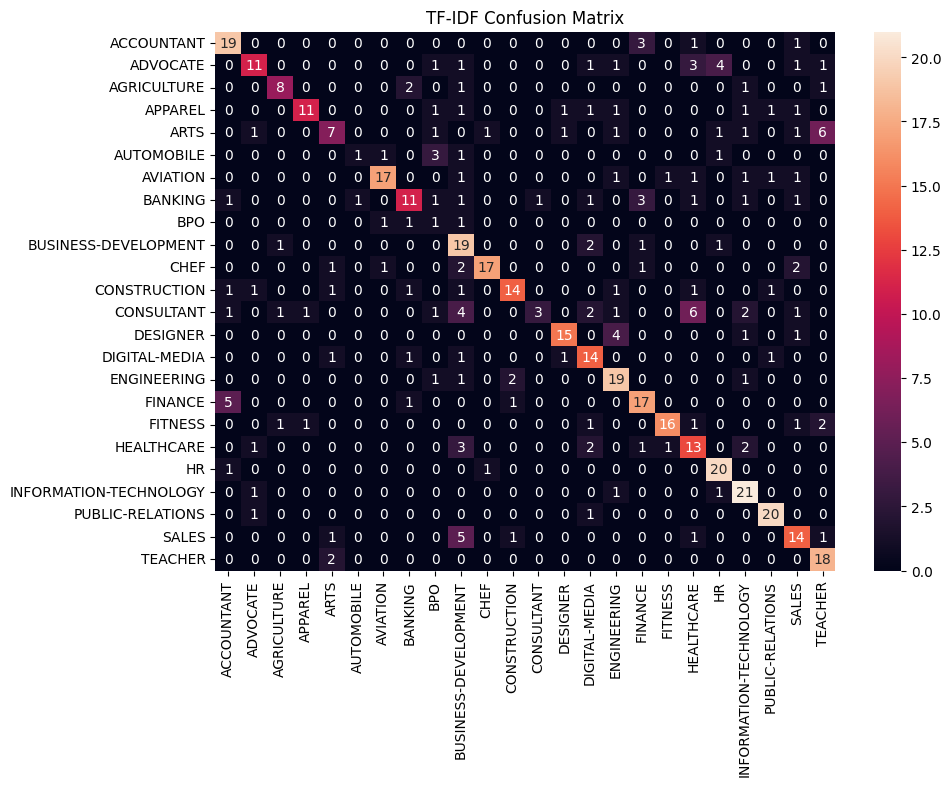

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=tfidf_model.named_steps["clf"].classes_)
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=tfidf_model.named_steps["clf"].classes_,
            yticklabels=tfidf_model.named_steps["clf"].classes_)
plt.title("TF-IDF Confusion Matrix")
plt.show()


In [14]:
joblib.dump(tfidf_model, "resume_tfidf_model.joblib")
print("Saved as resume_tfidf_model.joblib")

Saved as resume_tfidf_model.joblib


In [15]:
print("Loading sentence-transformer model...")
embedder = SentenceTransformer("all-MiniLM-L6-v2")  # lightweight and fast

print("Encoding train...")
X_train_emb = embedder.encode(X_train.tolist(), show_progress_bar=True)

print("Encoding test...")
X_test_emb = embedder.encode(X_test.tolist(), show_progress_bar=True)

bert_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
bert_clf.fit(X_train_emb, y_train)

print("Evaluating BERT model...")
y_pred_bert = bert_clf.predict(X_test_emb)
print("Accuracy:", accuracy_score(y_test, y_pred_bert))
print(classification_report(y_test, y_pred_bert))


Loading sentence-transformer model...
Encoding train...


Batches: 100%|██████████| 63/63 [03:34<00:00,  3.40s/it]


Encoding test...


Batches: 100%|██████████| 16/16 [00:25<00:00,  1.62s/it]


Evaluating BERT model...
Accuracy: 0.7022132796780685
                        precision    recall  f1-score   support

            ACCOUNTANT       0.79      0.92      0.85        24
              ADVOCATE       0.71      0.62      0.67        24
           AGRICULTURE       0.75      0.69      0.72        13
               APPAREL       0.67      0.32      0.43        19
                  ARTS       0.67      0.29      0.40        21
            AUTOMOBILE       0.10      0.14      0.12         7
              AVIATION       0.62      0.67      0.64        24
               BANKING       0.71      0.52      0.60        23
                   BPO       0.17      0.25      0.20         4
  BUSINESS-DEVELOPMENT       0.81      0.92      0.86        24
                  CHEF       0.95      0.83      0.89        24
          CONSTRUCTION       0.89      0.77      0.83        22
            CONSULTANT       0.70      0.70      0.70        23
              DESIGNER       0.86      0.86      

In [16]:
joblib.dump({
    "clf": bert_clf,
    "embedder_name": "all-MiniLM-L6-v2"
}, "resume_bert_model.joblib")

print("Saved as resume_bert_model.joblib")


Saved as resume_bert_model.joblib


In [17]:
sample_text = X_test.iloc[0]
print("TEXT:", sample_text[:400], "...")

print("\nTF-IDF Prediction:", tfidf_model.predict([sample_text])[0])

emb = embedder.encode([sample_text])
print("BERT Prediction:", bert_clf.predict(emb)[0])


TEXT: product designer professional summary 4-5 years engineering experience and 1-2 years working experience. able to work independently and under pressure, detail oriented, excellent problem solver, innovator. efficient mechanical engineer leveraging a strong technical background in bringing products from the laboratory to mass-manufacturing. mechanical engineer with  number    years of training in va ...

TF-IDF Prediction: ENGINEERING
BERT Prediction: ENGINEERING


In [19]:
import pandas as pd
import numpy as np
import re
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from torch.utils.data import Dataset, DataLoader

from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    Trainer,
    TrainingArguments
)

import warnings
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cpu'

In [21]:
def clean_text(text):
    if not isinstance(text, str):
        text = str(text)

    text = text.replace("\n", " ").replace("\r", " ")
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^A-Za-z0-9.,;:()/%\- ]+', ' ', text)
    return text.lower().strip()


In [22]:
df = pd.read_csv("resumes_extracted.csv")

# Clean text
df["clean_text"] = df["text"].apply(clean_text)

# Encode labels
label_encoder = LabelEncoder()
df["label_id"] = label_encoder.fit_transform(df["label"])

num_labels = len(label_encoder.classes_)
num_labels


24

In [23]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label_id"]
)

len(train_df), len(test_df)


(1987, 497)

In [24]:
tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

class ResumeDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = texts.tolist()
        self.labels = labels.tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length
        )
        return {
            "input_ids": torch.tensor(encoding["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(encoding["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = ResumeDataset(train_df["clean_text"], train_df["label_id"], tokenizer)
test_dataset  = ResumeDataset(test_df["clean_text"], test_df["label_id"], tokenizer)


In [25]:
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=num_labels
).to(device)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [28]:
import inspect
from transformers import TrainingArguments, __version__ as hf_version

print("Installed transformers version:", hf_version)


Installed transformers version: 4.57.1


In [31]:
from transformers import TrainingArguments
import inspect

# These arguments ALWAYS work across old/new versions
desired_args = {
    "output_dir": "bert_finetuned_output",
    "learning_rate": 2e-5,
    "per_device_train_batch_size": 8,
    "per_device_eval_batch_size": 8,
    "num_train_epochs": 3,
    "weight_decay": 0.01,
    "logging_steps": 50,
}

# Automatically filter unsupported args
sig = inspect.signature(TrainingArguments.__init__)
supported = set(sig.parameters.keys()) - {"self"}
filtered_args = {k: v for k, v in desired_args.items() if k in supported}

training_args = TrainingArguments(**filtered_args)

training_args


TrainingArguments(
_n_gpu=0,
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adafactor=False,
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=False,
do_predict=False,
do_train=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=False,
eval_steps=None,
eval_strategy=IntervalStrategy.NO,
eval_use_gather_object=False,
f

In [36]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,     # do_eval=True is implicit
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)


In [37]:
# compute_metrics function (works on all transformers versions)
def compute_metrics(eval_pred):
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro"
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


In [38]:
trainer.train()


Step,Training Loss
50,3.155500
100,2.981400
150,2.644700
200,2.285900
250,2.029400
300,1.697900
350,1.471900
400,1.373900
450,1.323100
500,1.189400


TrainOutput(global_step=747, training_loss=1.68590125373728, metrics={'train_runtime': 1511.4436, 'train_samples_per_second': 3.944, 'train_steps_per_second': 0.494, 'total_flos': 394973984526336.0, 'train_loss': 1.68590125373728, 'epoch': 3.0})

In [39]:
metrics = trainer.evaluate()
metrics


{'eval_loss': 1.0130454301834106,
 'eval_accuracy': 0.7887323943661971,
 'eval_precision': 0.7244663331166955,
 'eval_recall': 0.7252573402315966,
 'eval_f1': 0.7131003515533522,
 'eval_runtime': 24.8209,
 'eval_samples_per_second': 20.023,
 'eval_steps_per_second': 2.538,
 'epoch': 3.0}

In [40]:
trainer.save_model("resume_bert_finetuned")
tokenizer.save_pretrained("resume_bert_finetuned")

import joblib
joblib.dump(label_encoder, "resume_bert_finetuned/label_encoder.joblib")

print("Model saved to resume_bert_finetuned/")


Model saved to resume_bert_finetuned/


In [41]:
def predict_resume(text):
    model.eval()
    cleaned = clean_text(text)
    inputs = tokenizer(
        cleaned,
        return_tensors="pt",
        padding="max_length",
        truncation=True,
        max_length=256
    )

    # move to GPU/CPU
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits
    
    pred_id = torch.argmax(logits, dim=1).item()
    return label_encoder.inverse_transform([pred_id])[0]


In [42]:
sample_text = test_df["clean_text"].iloc[0]

print("TEXT:", sample_text[:500], "...\n")
print("Predicted Category:", predict_resume(sample_text))
print("Actual Category:", test_df["label"].iloc[0])


TEXT: product designer professional summary 4-5 years engineering experience and 1-2 years working experience. able to work independently and under pressure, detail oriented, excellent problem solver, innovator. efficient mechanical engineer leveraging a strong technical background in bringing products from the laboratory to mass-manufacturing. mechanical engineer with  number    years of training in varied industries, including manufacturing and high-tech environments. creative manufacturing engineer ...

Predicted Category: DESIGNER
Actual Category: DESIGNER


ALL COMPARISON

In [43]:
import pandas as pd

results = []

# -------------------------------
# 1. TF-IDF Model Results
# -------------------------------
y_pred_tfidf = tfidf_model.predict(X_test)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

precision_tfidf, recall_tfidf, f1_tfidf, _ = precision_recall_fscore_support(
    y_test, y_pred_tfidf, average="macro"
)

results.append({
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_tfidf),
    "Precision": precision_tfidf,
    "Recall": recall_tfidf,
    "F1 Score": f1_tfidf
})

# -------------------------------
# 2. BERT Embeddings + Logistic Regression
# -------------------------------
precision_emb, recall_emb, f1_emb, _ = precision_recall_fscore_support(
    y_test, y_pred_bert, average="macro"
)

results.append({
    "Model": "BERT Embeddings + Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_bert),
    "Precision": precision_emb,
    "Recall": recall_emb,
    "F1 Score": f1_emb
})

# -------------------------------
# 3. Fine-Tuned BERT Model
# -------------------------------
metrics_finetuned = trainer.evaluate()

results.append({
    "Model": "Fine-tuned DistilBERT",
    "Accuracy": metrics_finetuned["eval_accuracy"],
    "Precision": metrics_finetuned["eval_precision"],
    "Recall": metrics_finetuned["eval_recall"],
    "F1 Score": metrics_finetuned["eval_f1"],
})

# Make a pretty comparison table
comparison_df = pd.DataFrame(results)
comparison_df


,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,0.655936,0.660735,0.626575,0.617991
1,BERT Embeddings + Logistic Regression,0.702213,0.677084,0.667281,0.659800
2,Fine-tuned DistilBERT,0.788732,0.724466,0.725257,0.713100


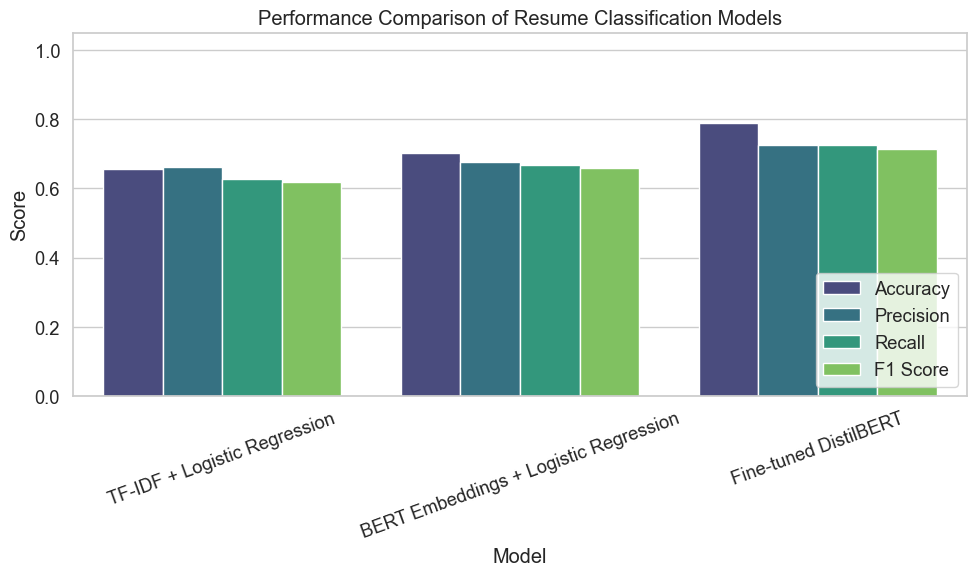

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.set(style="whitegrid", font_scale=1.2)

melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(
    data=melted,
    x="Model",
    y="Score",
    hue="Metric",
    palette="viridis"
)

plt.title("Performance Comparison of Resume Classification Models")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


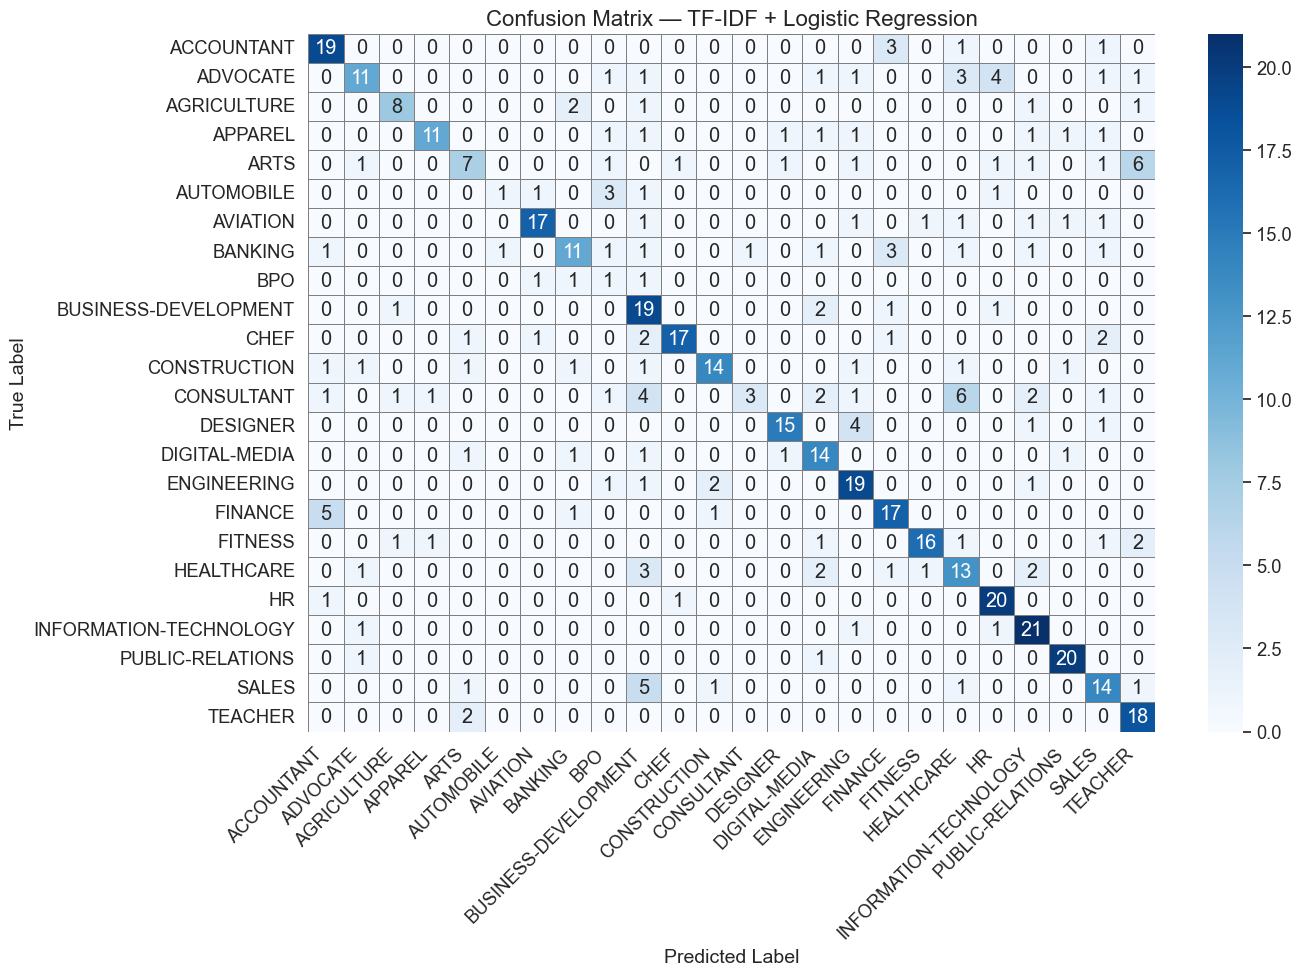

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predictions for TF-IDF model
y_pred_tfidf = tfidf_model.predict(X_test)

# Class order
labels = tfidf_model.named_steps["clf"].classes_

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_tfidf, labels=labels)

# Plot
plt.figure(figsize=(14, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
    linecolor='gray'
)

plt.title("Confusion Matrix — TF-IDF + Logistic Regression", fontsize=16)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


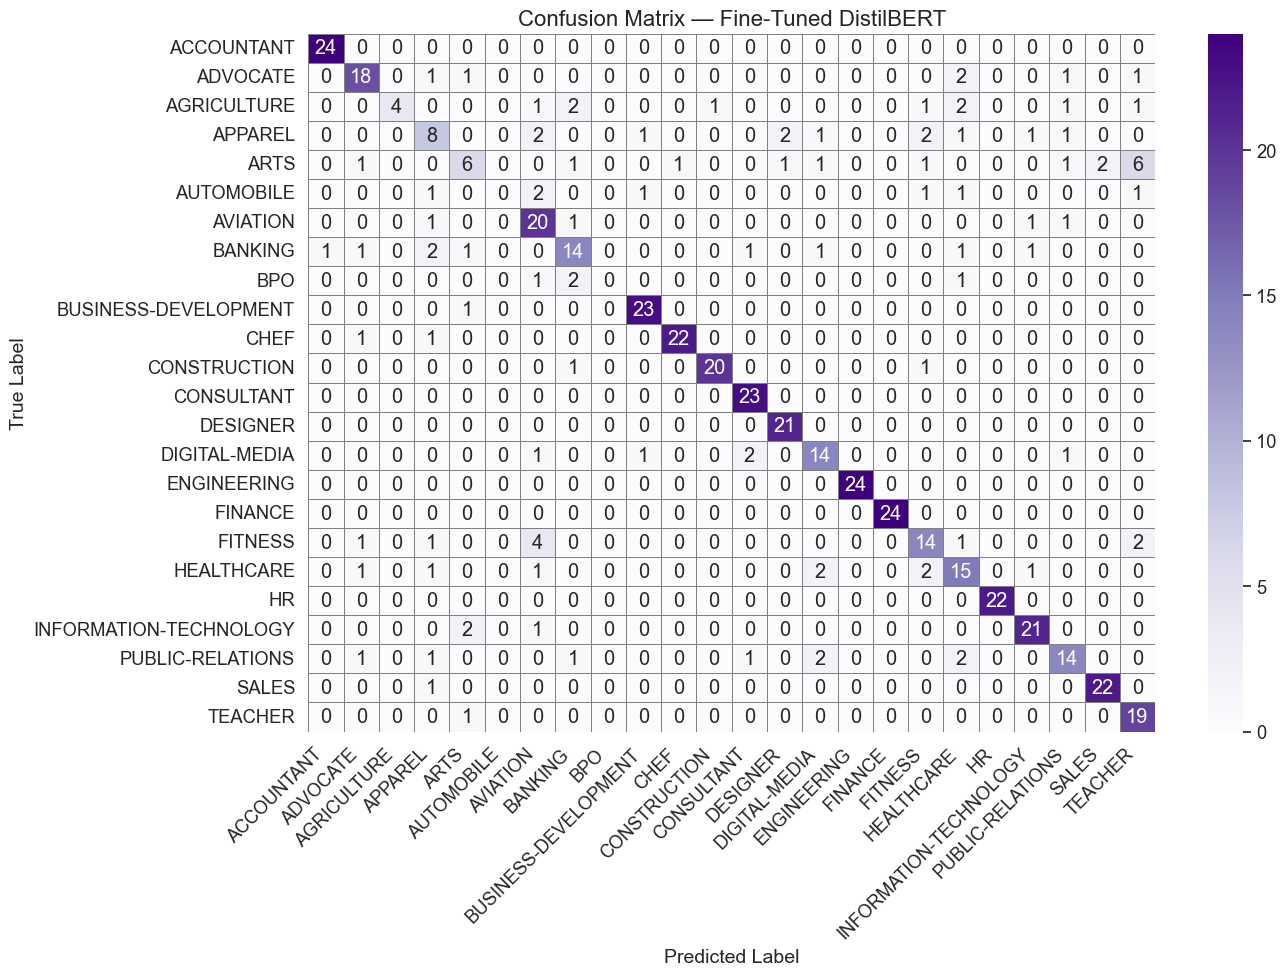

In [50]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict using the fine-tuned BERT model
bert_predictions = trainer.predict(test_dataset).predictions
y_pred_bert_finetuned = np.argmax(bert_predictions, axis=1)

# Label names
label_names = label_encoder.classes_

# Compute confusion matrix
cm_bert = confusion_matrix(test_df["label_id"], y_pred_bert_finetuned)

# Plot
plt.figure(figsize=(14, 10))
sns.heatmap(
    cm_bert,
    annot=True,
    fmt='d',
    cmap="Purples",
    xticklabels=label_names,
    yticklabels=label_names,
    cbar=True,
    linewidths=0.5,
    linecolor='gray'
)

plt.title("Confusion Matrix — Fine-Tuned DistilBERT", fontsize=16)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

